# 11. 랜덤 포레스트 분류 (Random Forest)

여러 개의 의사결정나무를 앙상블(배깅)하는 `RandomForestClassifier`의 기본 원리, `n_estimators`·`max_features='sqrt'` 설정, 특성 중요도(`feature_importances_`) 및 개별 트리(`estimators_[0]`) 시각화를 학습합니다.

원본 노트북 Lv2_Python_1119_RandomForest.ipynb

**Random Forest**

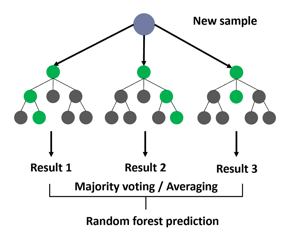

In [1]:
###################################################
from sklearn.ensemble import RandomForestClassifier
###################################################

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns; sns.set() # For a nicer plot style

In [2]:
# Iris dataset 로드
iris = load_iris()
X = iris.data
y = iris.target


In [3]:
import pandas as pd

# 데이터프레임으로 변환
df = pd.DataFrame(X, columns=iris.feature_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [5]:
# 모델 초기화 (객체 생성)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42) # 100 trees in the forest


In [6]:
# 모델 초기화 (객체 생성)
# rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, max_features=3) # 100 trees in the forest


In [ ]:
# 모델 설정 HyperParamter 확인 등
help(RandomForestClassifier)

# max_features='sqrt'


In [8]:
print(rf_clf.max_features)



sqrt


In [9]:
import math
result = math.sqrt(9) # 제곱근 함수
# print(result)  # Outputs: 3.0

print(math.sqrt(4))  # Outputs: 2.0

2.0


In [10]:
# 데이터의 속성 수를 구하고 'auto'에 해당하는 실제 값 계산
import numpy as np
n_features = X_train.shape[1]  # feature 수
max_features = int(np.sqrt(n_features))  # 'auto' 설정에 따른 실제 max_features값 계산

# print(n_features)
print(f"max_features 수: {max_features}")


max_features 수: 2


In [11]:
# 모델 학습
rf_clf.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [12]:
# Predict the test dataset
predictions = rf_clf.predict(X_test)

# 모델 성능 -  accuracy
accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy*100:.2f}%")


Accuracy: 100.00%


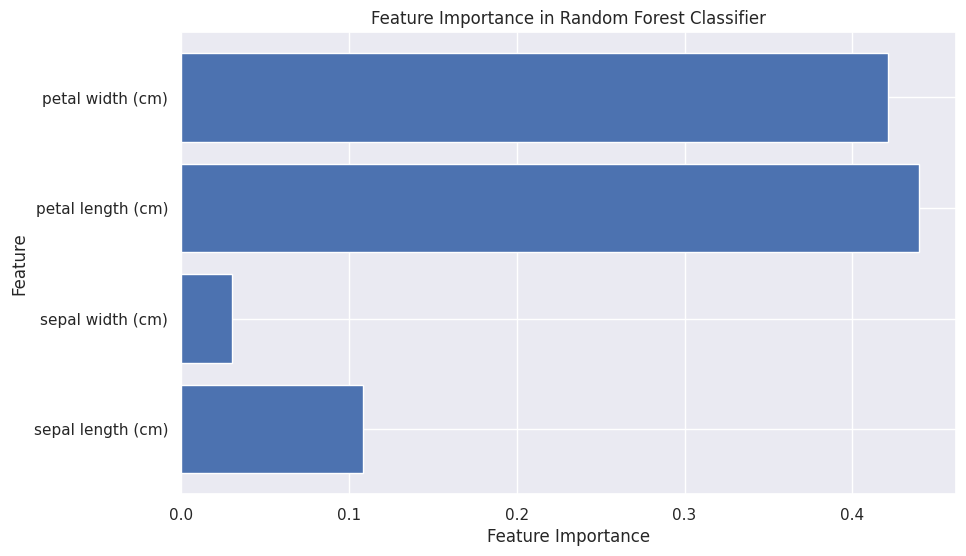

In [13]:
# Feature Importance
feature_importances = rf_clf.feature_importances_
features = iris.feature_names

plt.figure(figsize=(10, 6))
plt.barh(range(len(features)), feature_importances, align='center')
plt.yticks(range(len(features)), features)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Feature Importance in Random Forest Classifier')
plt.show()

In [14]:

from sklearn.tree import plot_tree


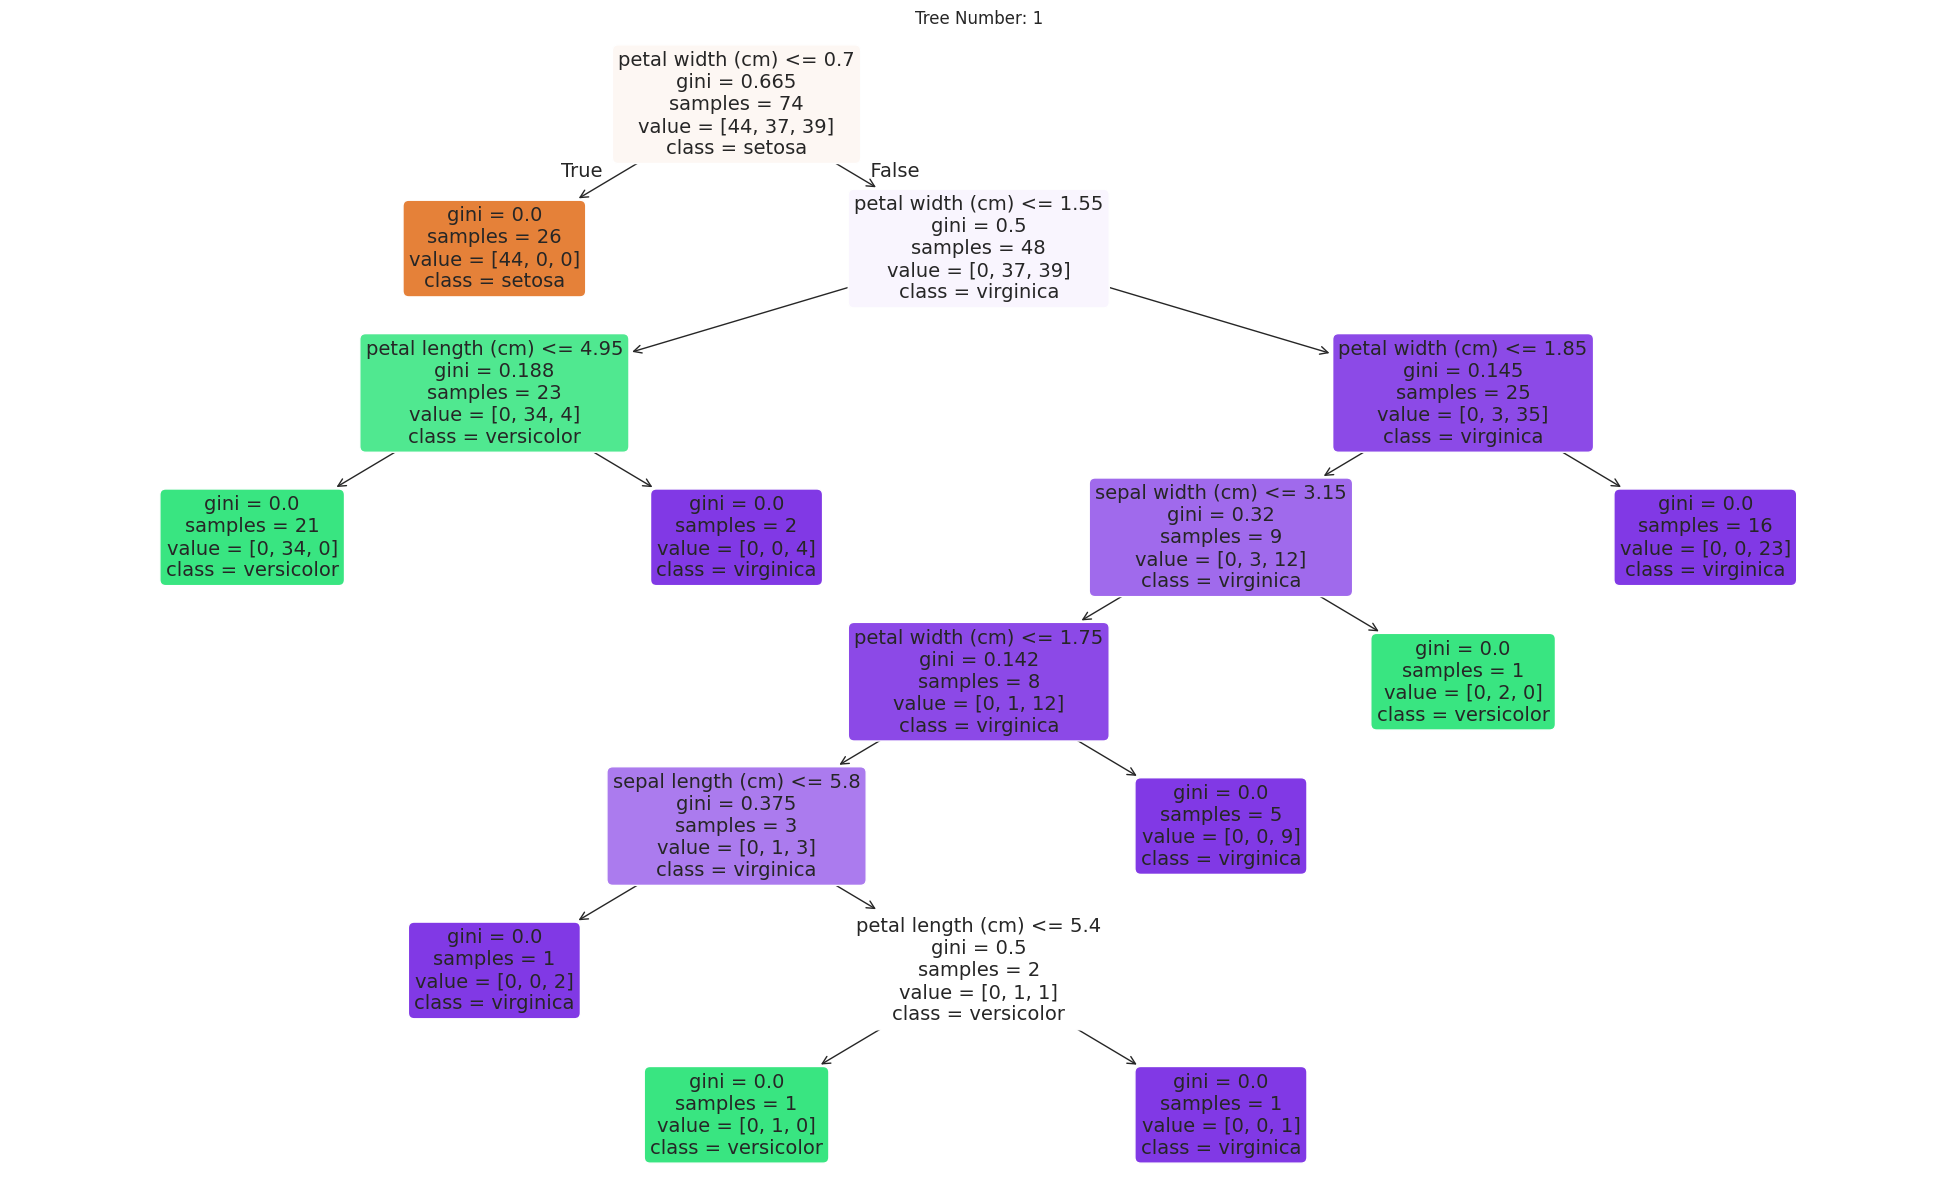

In [15]:
# 랜덤 포레스트의 첫 번째 결정 트리를 시각화
plt.figure(figsize=(25,15))
tree_index = 0  # 시각화할 트리의 인덱스
plot_tree(rf_clf.estimators_[tree_index], filled=True,
          feature_names=iris.feature_names,
          class_names=iris.target_names,
          rounded=True, fontsize=14)
plt.title(f'Tree Number: {tree_index + 1}')
plt.show()
